# Task 3 — Tahap 2b: Penentuan Jumlah Klaster dengan Kesepakatan Antar Modalitas dan Daftar Calon untuk DEC

**Mengapa tahap ini diperlukan.** Hasil tahap 2 menunjukkan empat hal yang membuat pemilihan jumlah klaster dan representasi belum meyakinkan:

1. **BIC dari GMM tidak informatif.** Nilai BIC terendah selalu jatuh di batas atas rentang (k = 12) pada hampir semua representasi, sehingga kriteria ini tidak menemukan puncak dan menarik median konsensus ke atas.
2. **Silhouette dan Davies-Bouldin cenderung menyukai k kecil** (sering k = 2) pada representasi yang berstruktur lemah, dan memberi nilai absolut rendah (di bawah 0,2) pada k = 4.
3. **Peringkat gabungan memberi bobot pada selisih NMI mikroskop yang hanya noise** (0,000 lawan 0,001), sehingga urutan teratas sebagian ditentukan oleh angka yang tidak bermakna.
4. **Pengeluaran representasi berdasarkan tebakan linear mikroskop terlalu keras.** Pada tahap 1 mikroskop dapat ditebak dari embedding SimCLR (akurasi seimbang 0,944), tetapi pada tahap 2 klaster K-Means di atasnya hampir tidak mengikuti mikroskop (NMI 0,012). Yang menentukan bagi pengelompokan adalah apakah *klaster* mengikuti alat, bukan apakah informasi alat ada di suatu arah ruang embedding. Gerbang kini memakai NMI klaster terhadap mikroskop.

Selain itu, kesepakatan klaster antara embedding gambar dan spektrum pada tahap 2 meningkat bersama k (ARI 0,13 pada k = 6 untuk *autoencoder*, 0,24 pada k = 8 untuk SimCLR dan spektrum), sehingga puncaknya mungkin berada di k yang lebih besar daripada yang diuji.

**Isi tahap ini.**
1. Kesepakatan klaster antar modalitas untuk k = 2 sampai 16 pada empat pasangan gambar-spektrum, sebagai kriteria jumlah klaster yang tidak bergantung pada geometri satu representasi: bila gambar dan spektrum sama-sama menggambarkan kelompok yang sama, pembagian yang ditemukan tiap modalitas secara terpisah akan paling mirip pada k yang sesuai.
2. Penetapan **k\*** dan himpunan k calon, memakai kesepakatan antar modalitas bersama stabilitas dan silhouette dari tahap 2.
3. Evaluasi tiap representasi pada k calon dengan ukuran tambahan **keseimbangan modalitas** (NMI klaster dengan klaster gambar dan dengan klaster spektrum), serta gerbang NMI mikroskop.
4. **Daftar calon untuk DEC** (representasi × k) beserta pusat dan label K-Means sebagai inisialisasi.

**Alur.** 0 Persiapan → 1 Kesepakatan antar modalitas → 2 Penetapan k\* → 3 Evaluasi representasi pada k calon → 4 Serah-terima → 5 Kesimpulan → 6 Commit.

In [4]:
AKUN_GITHUB = 'rafiptrnto'
EMAIL_GITHUB = 'rafiputranto665@gmail.com'

SEED = 0
K_MAKS = 16
N_SIL = 8000
GERBANG_NMI_MIK = 0.05      # klaster dianggap mengikuti mikroskop bila NMI di atas nilai ini
SPEKTRUM_REF = ['ae_spektrum', 'pca_spektrum']
GAMBAR_REF = ['ae_gambar', 'simclr_gambar']

import numpy, pandas, sklearn, sys, warnings, time, json, os
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


In [5]:
if not os.path.exists('/content/data/clustering_meta.csv'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git checkout main
!git pull --no-edit upstream main
assert os.path.exists('kode/task3_cluster/hasil/kriteria_k.csv'), "Hasil tahap 2 belum ada di main."
!git checkout -B task3-lanjutan
!mkdir -p kode/task3_cluster/serah_terima_v2
!ls kode/task3_cluster

/content/UTSDEEPLEARNING
Switched to branch 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
Already up to date.
Switched to and reset branch 'task3-lanjutan'
bobot		clu_data.py   emb    serah_terima     task3_klaster.ipynb
clu_cluster.py	clu_model.py  hasil  serah_terima_v2  task3_representasi.ipynb


### Kode pendukung

`clu_cluster.py` diperbarui dengan tiga fungsi baru (fungsi lama tidak berubah): `kontribusi_modalitas`, `evaluasi_rep_k`, dan `peringkat_k_tetap`.

In [6]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py
"""Pengelompokan klasik dan kriteria jumlah klaster untuk Task 3 (tahap 2). Tanpa PyTorch."""
import json, numpy as np, pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)


def muat_emb(folder):
    man = json.load(open(f'{folder}/manifest.json'))
    emb = {k: np.load(f'{folder}/{k}.npy').astype(np.float32) for k in man['embedding']}
    return emb, man


def kmeans(emb, k, seed=0, n_init=3):
    return KMeans(k, n_init=n_init, random_state=seed).fit(emb)


def gmm_label(emb, k, d_pca=16, seed=0):
    """GMM kovarians diagonal pada PCA d_pca dimensi. Mengembalikan (label, BIC)."""
    z = PCA(min(d_pca, emb.shape[1]), random_state=seed).fit_transform(emb)
    g = GaussianMixture(k, covariance_type='diag', n_init=2, reg_covar=1e-4, random_state=seed).fit(z)
    return g.predict(z), float(g.bic(z))


def aglo_prototipe(emb, k, n_proto=600, seed=0):
    """Agglomerative (Ward) pada n_proto prototipe K-Means, lalu tiap sampel mengikuti prototipenya.
    Ward langsung pada 36.000 sampel memerlukan matriks jarak terlalu besar."""
    km = KMeans(min(n_proto, len(emb) // 5), n_init=1, random_state=seed).fit(emb)
    lab_p = AgglomerativeClustering(k, linkage='ward').fit_predict(km.cluster_centers_)
    return lab_p[km.labels_]


def kestabilan(emb, k, ulang=3, seed=0, frac=0.5):
    """ARI antar dua K-Means yang dilatih pada separuh sampel acak berbeda, keduanya memberi label seluruh data."""
    rng = np.random.RandomState(seed)
    r = []
    for _ in range(ulang):
        p = rng.permutation(len(emb))
        a, b = p[:int(len(emb) * frac)], p[int(len(emb) * frac):]
        ka, kb = KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[a]), KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[b])
        r.append(adjusted_rand_score(ka.predict(emb), kb.predict(emb)))
    return float(np.mean(r))


def kriteria_k(emb, ks, n_sil=8000, seed=0, d_pca=16):
    """Per k: inersia, silhouette (sub-sampel), Davies-Bouldin, Calinski-Harabasz, BIC GMM, kestabilan."""
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    out = []
    for k in ks:
        km = kmeans(emb, k, seed)
        _, bic = gmm_label(emb, k, d_pca, seed)
        out.append(dict(k=int(k), inersia=float(km.inertia_),
                        silhouette=float(silhouette_score(emb[isub], km.labels_[isub])),
                        dbi=float(davies_bouldin_score(emb, km.labels_)),
                        ch=float(calinski_harabasz_score(emb, km.labels_)),
                        bic=bic, kestabilan=kestabilan(emb, k, seed=seed)))
    return pd.DataFrame(out)


def k_pilihan(df, ambang_stab=0.8):
    """k yang dipilih tiap kriteria. Kestabilan: k terbesar dengan ARI >= ambang (bila tak ada: k dengan ARI tertinggi).
    Konsensus: median dari empat kriteria, dibulatkan."""
    p = dict(silhouette=int(df.loc[df.silhouette.idxmax(), 'k']),
             dbi=int(df.loc[df.dbi.idxmin(), 'k']),
             bic=int(df.loc[df.bic.idxmin(), 'k']))
    ok = df[df.kestabilan >= ambang_stab]
    p['kestabilan'] = int(ok.k.max()) if len(ok) else int(df.loc[df.kestabilan.idxmax(), 'k'])
    p['konsensus'] = int(round(float(np.median([p['silhouette'], p['dbi'], p['bic'], p['kestabilan']]))))
    return p


def uji_mikroskop(label, mik):
    """ARI dan NMI klaster terhadap mikroskop (dekat 0 = klaster tidak mengikuti alat) serta kemurnian mikroskop terbesar."""
    mik = np.asarray(mik).astype(str)
    lab = np.asarray(label)
    ms = np.unique(mik)
    murni = 0.0
    for c in np.unique(lab):
        i = lab == c
        murni += max((mik[i] == m).sum() for m in ms)
    return dict(ari=float(adjusted_rand_score(mik, lab)), nmi=float(normalized_mutual_info_score(mik, lab)),
                kemurnian=float(murni / len(lab)), mayoritas=float(max((mik == m).mean() for m in ms)))


def ukuran_pada_k(emb, k, mik, seed=0, n_sil=8000):
    km = kmeans(emb, k, seed)
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    u = uji_mikroskop(km.labels_, mik)
    return dict(silhouette=float(silhouette_score(emb[isub], km.labels_[isub])), dbi=float(davies_bouldin_score(emb, km.labels_)),
                kestabilan=kestabilan(emb, k, seed=seed), mik_nmi=u['nmi'], mik_ari=u['ari'], mik_kemurnian=u['kemurnian'],
                ukuran_min=float(np.bincount(km.labels_).min() / len(emb))), km


def peringkat_gabungan(df):
    """Rerata peringkat: silhouette tinggi, DBI rendah, kestabilan tinggi, NMI mikroskop rendah."""
    r = pd.DataFrame({'silhouette': df.silhouette.rank(ascending=False), 'dbi': df.dbi.rank(ascending=True),
                      'kestabilan': df.kestabilan.rank(ascending=False), 'mik_nmi': df.mik_nmi.rank(ascending=True)}, index=df.index)
    return r.mean(1)


def kesesuaian_modalitas(ea, eb, ks=range(2, 9), seed=0):
    """Kesepakatan pengelompokan dari dua modalitas: ARI dan NMI antara K-Means pada embedding A dan pada embedding B,
    untuk tiap k. Nilai dasar (permutasi label B) mendekati 0."""
    rng = np.random.RandomState(seed)
    out = []
    for k in ks:
        la, lb = kmeans(ea, k, seed).labels_, kmeans(eb, k, seed).labels_
        out.append(dict(k=int(k), ari=float(adjusted_rand_score(la, lb)), nmi=float(normalized_mutual_info_score(la, lb)),
                        ari_acak=float(adjusted_rand_score(la, rng.permutation(lb)))))
    return pd.DataFrame(out)


def kontribusi_modalitas(lab, refs_g, refs_s):
    """NMI label terhadap klaster satu-modalitas: rata-rata atas referensi gambar dan atas referensi spektrum."""
    g = float(np.mean([normalized_mutual_info_score(lab, r) for r in refs_g]))
    s = float(np.mean([normalized_mutual_info_score(lab, r) for r in refs_s]))
    return g, s


def evaluasi_rep_k(emb, k, mik, refs_g, refs_s, seed=0, n_sil=8000):
    """Mutu K-Means pada satu k, diagnosis mikroskop, dan seberapa seimbang klaster mewakili gambar dan spektrum."""
    u, km = ukuran_pada_k(emb, k, mik, seed, n_sil)
    g, s = kontribusi_modalitas(km.labels_, refs_g, refs_s)
    u.update(nmi_gambar=g, nmi_spektrum=s, seimbang=min(g, s))
    return u, km


def peringkat_k_tetap(df):
    """Rerata peringkat pada k tetap: silhouette tinggi, DBI rendah, kestabilan tinggi, keseimbangan modalitas tinggi."""
    r = pd.DataFrame({'silhouette': df.silhouette.rank(ascending=False), 'dbi': df.dbi.rank(ascending=True),
                      'kestabilan': df.kestabilan.rank(ascending=False), 'seimbang': df.seimbang.rank(ascending=False)}, index=df.index)
    return r.mean(1)


Overwriting /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py


In [7]:
sys.path.insert(0, '/content/UTSDEEPLEARNING/kode/task3_cluster')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, clu_cluster
importlib.reload(clu_cluster)
from clu_cluster import *
from IPython.display import display, Markdown
OUT = '/content/UTSDEEPLEARNING/kode/task3_cluster'
INFO = {}

EMB, MAN = muat_emb(f'{OUT}/emb')
meta = pd.read_csv('/content/data/clustering_meta.csv')
if 'indeks' in meta.columns: meta = meta.sort_values('indeks').reset_index(drop=True)
mik = meta['mikroskop'].astype(str).values
assert all(len(e) == len(mik) for e in EMB.values())
KRIT = pd.read_csv(f'{OUT}/hasil/kriteria_k.csv')
print(list(EMB))

['pca_gambar', 'pca_spektrum', 'pca_fusi', 'ae_gambar', 'simclr_gambar', 'ae_spektrum', 'fusi_ae_concat', 'fusi_simclr_concat', 'fusi_gabungan']


## 1. Kesepakatan klaster antar modalitas untuk k = 2 sampai 16

Untuk setiap pasangan embedding gambar dan embedding spektrum, K-Means dijalankan terpisah pada masing-masing lalu dihitung ARI dan NMI antara kedua pembagian. Empat pasangan dipakai: dua representasi gambar (*autoencoder* dan SimCLR) dikalikan dua representasi spektrum (*autoencoder* dan PCA). Pasangan dengan PCA gambar tidak disertakan karena pada tahap 2 kesepakatannya nol pada semua k. Nilai dasar adalah ARI antara satu pembagian dan hasil pengacakan pembagian lain (mendekati 0).

K-Means selesai | 48 dtk


pasangan,ae_gambar x ae_spektrum,ae_gambar x pca_spektrum,simclr_gambar x ae_spektrum,simclr_gambar x pca_spektrum,rata-rata
k,,,,,
2,0.000,0.000,0.000,0.000,0.000
3,0.000,0.000,-0.001,0.000,0.000
4,0.027,0.019,0.076,0.060,0.046
5,0.119,0.078,0.139,0.092,0.107
6,0.133,0.086,0.160,0.103,0.120
7,0.126,0.072,0.186,0.136,0.130
8,0.109,0.076,0.237,0.179,0.150
9,0.134,0.092,0.250,0.196,0.168
10,0.102,0.092,0.220,0.181,0.149


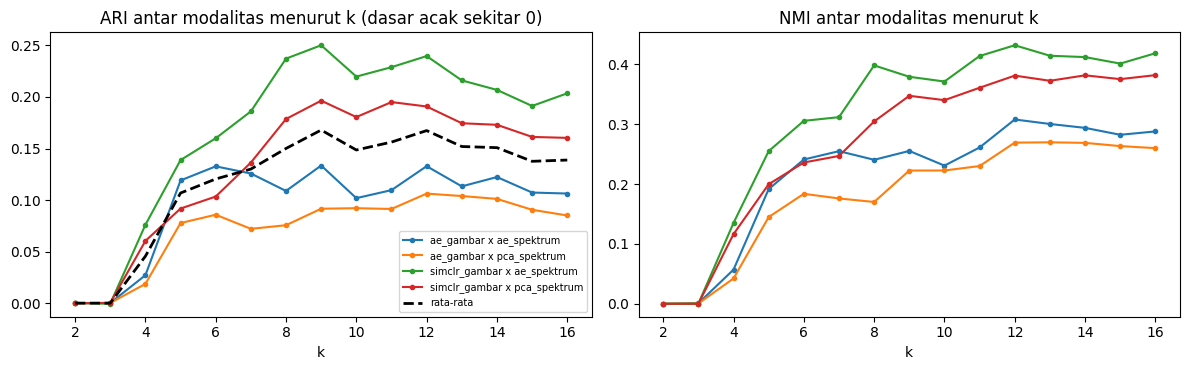

In [8]:
t0 = time.time()
PAS = [(g, s) for g in GAMBAR_REF for s in SPEKTRUM_REF]
KS = list(range(2, K_MAKS + 1))
# K-Means sekali per representasi per k, lalu dihitung semua pasangan
LAB = {n: {k: kmeans(EMB[n], k, SEED).labels_ for k in KS} for n in set(GAMBAR_REF + SPEKTRUM_REF)}
print(f"K-Means selesai | {time.time() - t0:.0f} dtk")
rng = np.random.RandomState(SEED)
baris = []
for g, s in PAS:
    for k in KS:
        a, b = LAB[g][k], LAB[s][k]
        baris.append(dict(pasangan=f"{g} x {s}", k=k, ari=adjusted_rand_score(a, b), nmi=normalized_mutual_info_score(a, b),
                          ari_acak=adjusted_rand_score(a, rng.permutation(b))))
SIL = pd.DataFrame(baris)
SIL.to_csv(f'{OUT}/hasil/kesepakatan_modalitas_k2_16.csv', index=False)
tab = SIL.pivot(index='k', columns='pasangan', values='ari')
tab['rata-rata'] = tab.mean(1)
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for nama, d in SIL.groupby('pasangan'):
    ax[0].plot(d.k, d.ari, marker='o', ms=3, label=nama); ax[1].plot(d.k, d.nmi, marker='o', ms=3, label=nama)
ax[0].plot(tab.index, tab['rata-rata'], 'k--', lw=2, label='rata-rata')
ax[0].set_title("ARI antar modalitas menurut k (dasar acak sekitar 0)"); ax[1].set_title("NMI antar modalitas menurut k")
ax[0].legend(fontsize=7)
for a_ in ax: a_.set_xlabel('k')
plt.tight_layout(); plt.show()
INFO['kesepakatan'] = tab.round(4).reset_index().to_dict('records')

## 2. Penetapan k\* dan himpunan k calon

**k\*** adalah k dengan rata-rata ARI antar modalitas tertinggi. Bila puncak jatuh di batas rentang (k = 16) atau kurva datar sehingga puncaknya tidak tegas (ARI k\* kurang dari 10% lebih tinggi daripada rata-rata tiga k terdekat), hal itu dilaporkan dan himpunan calon diperluas. Sebagai pemeriksaan silang, ditampilkan juga k terbaik menurut silhouette dan kestabilan dari tahap 2 untuk representasi yang tidak dikeluarkan. BIC tidak dipakai karena tidak menemukan puncak (lihat bagian pendahuluan); fakta itu dicatat di bawah.

**Himpunan k calon** adalah k\*−2, k\*, dan k\*+2 (batas bawah 3, batas atas 16). Tahap berikutnya (DEC) mengevaluasi ketiganya.

In [9]:
rata = tab['rata-rata']
K_STAR = int(rata.idxmax())
tepi = (K_STAR == K_MAKS)
tetangga = [k for k in (K_STAR - 2, K_STAR - 1, K_STAR + 1, K_STAR + 2) if k in rata.index]
tegas = bool(rata[K_STAR] > 1.1 * float(np.mean([rata[k] for k in tetangga])))
K_SET = sorted({max(3, K_STAR - 2), K_STAR, min(K_MAKS, K_STAR + 2)})
print(f"k* (rata-rata ARI antar modalitas tertinggi) = {K_STAR} | ARI = {rata[K_STAR]:.3f} | di batas rentang: {tepi} | puncak tegas: {tegas}")
print("himpunan k calon:", K_SET)

# pemeriksaan silang dari tahap 2 (tanpa representasi yang tidak punya struktur: dibaca apa adanya)
sub = KRIT[KRIT.representasi.isin(['ae_gambar', 'simclr_gambar', 'ae_spektrum', 'fusi_gabungan', 'fusi_simclr_concat', 'fusi_ae_concat'])]
ringkas = sub.groupby('representasi').apply(lambda d: pd.Series(dict(
    k_silhouette=int(d.loc[d.silhouette.idxmax(), 'k']), k_dbi=int(d.loc[d.dbi.idxmin(), 'k']), k_bic=int(d.loc[d.bic.idxmin(), 'k']),
    k_stab_ge_08=int(d[d.kestabilan >= 0.8].k.max()) if (d.kestabilan >= 0.8).any() else -1)))
display(ringkas)
bic_tepi = float((KRIT.groupby('representasi').apply(lambda d: d.loc[d.bic.idxmin(), 'k'] == d.k.max())).mean())
print(f"BIC terendah di batas atas rentang pada {bic_tepi * 100:.0f}% representasi")
INFO.update(k_star=K_STAR, k_set=K_SET, k_star_tepi=tepi, k_star_tegas=tegas, ari_k_star=float(rata[K_STAR]), bic_tepi_persen=bic_tepi * 100)

k* (rata-rata ARI antar modalitas tertinggi) = 9 | ARI = 0.168 | di batas rentang: False | puncak tegas: True
himpunan k calon: [7, 9, 11]


,k_silhouette,k_dbi,k_bic,k_stab_ge_08
representasi,,,,
ae_gambar,4,4,12,9
ae_spektrum,6,8,12,8
fusi_ae_concat,2,2,12,2
fusi_gabungan,4,6,12,9
fusi_simclr_concat,2,7,12,12
simclr_gambar,2,6,12,11


BIC terendah di batas atas rentang pada 89% representasi


## 3. Evaluasi representasi pada k calon

Setiap representasi dievaluasi dengan K-Means pada tiap k calon. Ukurannya: silhouette (sub-sampel), Davies-Bouldin, kestabilan (ARI dua K-Means pada separuh sampel berbeda), NMI terhadap mikroskop sebagai **gerbang** (di atas 0,05 dikeluarkan), serta **keseimbangan modalitas**: NMI klaster dengan klaster gambar-saja dan dengan klaster spektrum-saja (rata-rata dari referensi yang ditetapkan di awal), dan yang terkecil dari keduanya. Klaster dari satu modalitas saja bernilai mendekati 0 pada modalitas lainnya, sehingga ukuran ini menguntungkan klaster yang mencerminkan keduanya. Itu **heuristik**, bukan pembuktian: ia mengasumsikan bahwa satu kelompok laten yang sama memengaruhi gambar dan spektrum. Peringkat memakai rerata peringkat silhouette, Davies-Bouldin, kestabilan, dan keseimbangan modalitas, dihitung terpisah untuk setiap k karena nilai silhouette menurun alami bila k membesar.

In [10]:
t0 = time.time()
CALON = list(EMB.keys())
HASIL_K, KMS = {}, {}
for k in K_SET:
    refs_g = [kmeans(EMB[n], k, SEED).labels_ for n in GAMBAR_REF]
    refs_s = [kmeans(EMB[n], k, SEED).labels_ for n in SPEKTRUM_REF]
    baris = []
    for nama in CALON:
        u, km = evaluasi_rep_k(EMB[nama], k, mik, refs_g, refs_s, seed=SEED, n_sil=N_SIL)
        KMS[(nama, k)] = km
        baris.append(dict(representasi=nama, **u))
    d = pd.DataFrame(baris).set_index('representasi')
    d['lolos'] = d.mik_nmi <= GERBANG_NMI_MIK
    d['peringkat'] = np.nan
    d.loc[d.lolos, 'peringkat'] = peringkat_k_tetap(d[d.lolos])
    HASIL_K[k] = d.sort_values('peringkat')
    print(f"k = {k} selesai | {time.time() - t0:.0f} dtk")
    display(Markdown(f"**k = {k}**"))
    display(HASIL_K[k][['silhouette', 'dbi', 'kestabilan', 'mik_nmi', 'nmi_gambar', 'nmi_spektrum', 'seimbang', 'ukuran_min', 'lolos', 'peringkat']].round(3))
pd.concat(HASIL_K, names=['k']).to_csv(f'{OUT}/hasil/evaluasi_representasi_k_calon.csv')
INFO['evaluasi'] = {int(k): d.reset_index().to_dict('records') for k, d in HASIL_K.items()}

k = 7 selesai | 41 dtk


**k = 7**

,silhouette,dbi,kestabilan,mik_nmi,nmi_gambar,nmi_spektrum,seimbang,ukuran_min,lolos,peringkat
representasi,,,,,,,,,,
fusi_simclr_concat,0.164,1.838,0.855,0.025,0.470,0.411,0.411,0.035,True,1.50
fusi_gabungan,0.104,2.153,0.846,0.000,0.343,0.619,0.343,0.119,True,3.25
pca_spektrum,0.182,1.593,0.520,0.000,0.212,0.764,0.212,0.112,True,4.25
ae_spektrum,0.125,2.083,0.707,0.000,0.284,0.764,0.284,0.064,True,4.25
ae_gambar,0.074,2.741,0.819,0.000,0.606,0.216,0.216,0.065,True,5.25
pca_fusi,-0.070,4.112,0.808,0.000,0.396,0.507,0.396,0.002,True,5.50
pca_gambar,0.100,2.187,0.802,0.001,0.158,0.000,0.000,0.048,True,5.75
fusi_ae_concat,0.013,3.340,0.677,0.000,0.319,0.609,0.319,0.051,True,6.25
simclr_gambar,0.298,1.158,0.949,0.057,0.606,0.279,0.279,0.034,False,NaN


k = 9 selesai | 84 dtk


**k = 9**

,silhouette,dbi,kestabilan,mik_nmi,nmi_gambar,nmi_spektrum,seimbang,ukuran_min,lolos,peringkat
representasi,,,,,,,,,,
fusi_simclr_concat,0.156,2.018,0.901,0.049,0.557,0.446,0.446,0.035,True,1.75
fusi_gabungan,0.090,2.241,0.887,0.000,0.419,0.608,0.419,0.086,True,3.00
pca_spektrum,0.185,1.475,0.717,0.000,0.285,0.769,0.285,0.090,True,3.25
ae_spektrum,0.127,2.436,0.756,0.000,0.317,0.769,0.317,0.019,True,4.00
ae_gambar,0.065,2.694,0.846,0.000,0.637,0.239,0.239,0.034,True,5.50
pca_fusi,-0.048,3.092,0.605,0.000,0.489,0.544,0.489,0.001,True,5.75
pca_gambar,0.074,2.622,0.651,0.001,0.147,0.001,0.001,0.024,True,6.00
fusi_ae_concat,0.009,3.401,0.604,0.000,0.382,0.563,0.382,0.024,True,6.75
simclr_gambar,0.317,1.069,0.973,0.114,0.637,0.364,0.364,0.034,False,NaN


k = 11 selesai | 133 dtk


**k = 11**

,silhouette,dbi,kestabilan,mik_nmi,nmi_gambar,nmi_spektrum,seimbang,ukuran_min,lolos,peringkat
representasi,,,,,,,,,,
fusi_gabungan,0.088,2.419,0.780,0.000,0.413,0.676,0.413,0.051,True,2.25
pca_spektrum,0.178,1.519,0.694,0.000,0.296,0.822,0.296,0.060,True,2.75
ae_spektrum,0.118,2.204,0.688,0.000,0.338,0.822,0.338,0.026,True,3.25
pca_gambar,0.057,3.040,0.740,0.001,0.175,0.001,0.001,0.015,True,4.50
ae_gambar,0.041,2.737,0.697,0.000,0.630,0.246,0.246,0.031,True,4.50
pca_fusi,-0.062,3.149,0.617,0.000,0.431,0.548,0.431,0.001,True,5.00
fusi_ae_concat,-0.005,3.572,0.539,0.000,0.386,0.668,0.386,0.024,True,5.75
simclr_gambar,0.315,1.049,0.819,0.102,0.630,0.388,0.388,0.034,False,NaN
fusi_simclr_concat,0.147,2.009,0.848,0.097,0.534,0.482,0.482,0.030,False,NaN


## 4. Serah-terima ke tahap 3 (DEC)

Dari tiap k calon diambil tiga representasi teratas yang lolos gerbang mikroskop. Pusat dan label K-Means untuk setiap kombinasi (representasi, k) disimpan sebagai inisialisasi DEC, bersama `serah_terima_v2.json`. Daftar ini menggantikan serah-terima tahap 2 (yang memilih satu representasi pada k = 4).

In [11]:
ST = f'{OUT}/serah_terima_v2'
os.makedirs(ST, exist_ok=True)
daftar, reps = [], []
for k in K_SET:
    d = HASIL_K[k]
    atas = list(d[d.lolos].index[:3])
    for n in atas:
        km = KMS[(n, k)]
        np.save(f'{ST}/pusat_{n}_k{k}.npy', km.cluster_centers_.astype(np.float32))
        np.save(f'{ST}/label_{n}_k{k}.npy', km.labels_.astype(np.int16))
        daftar.append(dict(representasi=n, k=int(k), pusat=f'pusat_{n}_k{k}.npy', label=f'label_{n}_k{k}.npy',
                           peringkat=float(d.loc[n, 'peringkat']), silhouette=float(d.loc[n, 'silhouette']), kestabilan=float(d.loc[n, 'kestabilan']),
                           seimbang=float(d.loc[n, 'seimbang']), mik_nmi=float(d.loc[n, 'mik_nmi'])))
        reps.append(n)
terbanyak = pd.Series(reps).value_counts()
serah = dict(k_star=K_STAR, k_set=K_SET, gerbang_nmi_mikroskop=GERBANG_NMI_MIK, calon=daftar,
             representasi_paling_sering_teratas=list(terbanyak.index[:3]), seed=SEED)
with open(f'{ST}/serah_terima_v2.json', 'w') as f: json.dump(serah, f, indent=2)
with open(f'{OUT}/hasil/task3_lanjutan.json', 'w') as f: json.dump({'info': INFO}, f, indent=2, default=float)
print(terbanyak)
print(pd.DataFrame(daftar)[['representasi', 'k', 'peringkat', 'silhouette', 'kestabilan', 'seimbang', 'mik_nmi']].round(3).to_string())

fusi_gabungan         3
pca_spektrum          3
fusi_simclr_concat    2
ae_spektrum           1
Name: count, dtype: int64
         representasi   k  peringkat  silhouette  kestabilan  seimbang  mik_nmi
0  fusi_simclr_concat   7       1.50       0.164       0.855     0.411    0.025
1       fusi_gabungan   7       3.25       0.104       0.846     0.343    0.000
2        pca_spektrum   7       4.25       0.182       0.520     0.212    0.000
3  fusi_simclr_concat   9       1.75       0.156       0.901     0.446    0.049
4       fusi_gabungan   9       3.00       0.090       0.887     0.419    0.000
5        pca_spektrum   9       3.25       0.185       0.717     0.285    0.000
6       fusi_gabungan  11       2.25       0.088       0.780     0.413    0.000
7        pca_spektrum  11       2.75       0.178       0.694     0.296    0.000
8         ae_spektrum  11       3.25       0.118       0.688     0.338    0.000


## 5. Kesimpulan tahap 2b

Teks dibangkitkan otomatis dari hasil yang tercatat di atas.

In [12]:
def _f(x, n=2): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t3c(info, rentang_maks):
    p = []
    ks, ari, ks_set = info['k_star'], info['ari_k_star'], info['k_set']
    kal = []
    if info['k_star_tepi']: kal.append(f"puncak jatuh di batas rentang (k = {rentang_maks}), sehingga k yang sebenarnya mungkin lebih besar")
    if not info['k_star_tegas']: kal.append("puncak tidak tegas (kurva relatif datar di sekitar k*)")
    ket = (" Catatan: " + '; '.join(kal) + ".") if kal else " Puncaknya tegas dan tidak berada di batas rentang."
    p.append(f"**1. Jumlah klaster.** Kesepakatan klaster antara gambar dan spektrum (rata-rata ARI empat pasangan) tertinggi pada k* = {ks} (ARI {_f(ari, 3)}, dasar acak mendekati 0).{ket} "
             f"Himpunan k calon untuk DEC: {', '.join(map(str, ks_set))}. BIC terendah jatuh di batas atas rentang pada {_f(info['bic_tepi_persen'], 0)}% representasi, sehingga tidak dipakai sebagai kriteria.")
    if ari < 0.1:
        p.append("Kesepakatan antar modalitas rendah di semua k (ARI di bawah 0,1), sehingga kriteria ini hanya memberi petunjuk lemah dan jumlah klaster perlu dibaca sebagai kisaran.")
    ev = info['evaluasi']
    for k in ks_set:
        d = [r for r in ev[k] if r['lolos']]
        if not d: continue
        atas = ', '.join(f"{r['representasi']} (silhouette {_f(r['silhouette'])}, kestabilan {_f(r['kestabilan'])}, keseimbangan {_f(r['seimbang'], 3)})" for r in d[:3])
        p.append(f"**k = {k}.** Tiga teratas yang lolos gerbang mikroskop: {atas}.")
    gugur = sorted({r['representasi'] for k in ev for r in ev[k] if not r['lolos']})
    p.append("**2. Gerbang mikroskop.** " + (f"Representasi yang klasternya mengikuti mikroskop (NMI di atas 0,05) pada setidaknya satu k calon: {', '.join(gugur)}." if gugur
             else "Tidak ada representasi yang klasternya mengikuti mikroskop pada k calon mana pun (NMI tidak lebih dari 0,05)."))
    p.append("**3. Keterbatasan.** Seluruh ukuran bersifat internal. Keseimbangan modalitas adalah heuristik yang mengandaikan satu kelompok laten memengaruhi kedua modalitas; bila gambar dan spektrum sebenarnya menggambarkan kelompok yang berbeda, ukuran ini tidak memihak klaster yang benar. Kesepakatan antar modalitas dihitung dari K-Means yang bisa berbeda dengan metode yang akhirnya dipakai. Satu seed.")
    p.append("**4. Serah-terima.** Daftar calon (representasi × k) beserta pusat dan label K-Means tersimpan di `serah_terima_v2/`. Tahap 3 menjalankan DEC pada calon tersebut dan memilih konfigurasi akhir.")
    return '\n\n'.join(p)

KESIMPULAN = buat_kesimpulan_t3c(INFO, K_MAKS)
display(Markdown(KESIMPULAN))

**1. Jumlah klaster.** Kesepakatan klaster antara gambar dan spektrum (rata-rata ARI empat pasangan) tertinggi pada k* = 9 (ARI 0,168, dasar acak mendekati 0). Puncaknya tegas dan tidak berada di batas rentang. Himpunan k calon untuk DEC: 7, 9, 11. BIC terendah jatuh di batas atas rentang pada 89% representasi, sehingga tidak dipakai sebagai kriteria.

**k = 7.** Tiga teratas yang lolos gerbang mikroskop: fusi_simclr_concat (silhouette 0,16, kestabilan 0,85, keseimbangan 0,411), fusi_gabungan (silhouette 0,10, kestabilan 0,85, keseimbangan 0,343), pca_spektrum (silhouette 0,18, kestabilan 0,52, keseimbangan 0,212).

**k = 9.** Tiga teratas yang lolos gerbang mikroskop: fusi_simclr_concat (silhouette 0,16, kestabilan 0,90, keseimbangan 0,446), fusi_gabungan (silhouette 0,09, kestabilan 0,89, keseimbangan 0,419), pca_spektrum (silhouette 0,18, kestabilan 0,72, keseimbangan 0,285).

**k = 11.** Tiga teratas yang lolos gerbang mikroskop: fusi_gabungan (silhouette 0,09, kestabilan 0,78, keseimbangan 0,413), pca_spektrum (silhouette 0,18, kestabilan 0,69, keseimbangan 0,296), ae_spektrum (silhouette 0,12, kestabilan 0,69, keseimbangan 0,338).

**2. Gerbang mikroskop.** Representasi yang klasternya mengikuti mikroskop (NMI di atas 0,05) pada setidaknya satu k calon: fusi_simclr_concat, simclr_gambar.

**3. Keterbatasan.** Seluruh ukuran bersifat internal. Keseimbangan modalitas adalah heuristik yang mengandaikan satu kelompok laten memengaruhi kedua modalitas; bila gambar dan spektrum sebenarnya menggambarkan kelompok yang berbeda, ukuran ini tidak memihak klaster yang benar. Kesepakatan antar modalitas dihitung dari K-Means yang bisa berbeda dengan metode yang akhirnya dipakai. Satu seed.

**4. Serah-terima.** Daftar calon (representasi × k) beserta pusat dan label K-Means tersimpan di `serah_terima_v2/`. Tahap 3 menjalankan DEC pada calon tersebut dan memilih konfigurasi akhir.

## 6. Commit ke branch `task3-lanjutan`

Setelah sel ini, simpan notebook dengan **File → Save a copy in GitHub** (repositori fork, branch `task3-lanjutan`, path `kode/task3_cluster/task3_lanjutan.ipynb`), lalu buka *pull request* ke repositori organisasi.

In [13]:
with open(f'{OUT}/hasil/kesimpulan_task3_lanjutan.md', 'w') as f: f.write(KESIMPULAN)
%cd /content/UTSDEEPLEARNING
!git add kode/task3_cluster/clu_cluster.py kode/task3_cluster/hasil kode/task3_cluster/serah_terima_v2
!git commit -m "Task 3 tahap 2b: kesepakatan antar modalitas untuk k, evaluasi pada k calon, daftar calon DEC"
!git push origin task3-lanjutan

/content/UTSDEEPLEARNING
[task3-lanjutan e634538] Task 3 tahap 2b: kesepakatan antar modalitas untuk k, evaluasi pada k calon, daftar calon DEC
 24 files changed, 789 insertions(+)
 create mode 100644 kode/task3_cluster/hasil/evaluasi_representasi_k_calon.csv
 create mode 100644 kode/task3_cluster/hasil/kesepakatan_modalitas_k2_16.csv
 create mode 100644 kode/task3_cluster/hasil/kesimpulan_task3_lanjutan.md
 create mode 100644 kode/task3_cluster/hasil/task3_lanjutan.json
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_ae_spektrum_k11.npy
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_fusi_gabungan_k11.npy
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_fusi_gabungan_k7.npy
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_fusi_gabungan_k9.npy
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_fusi_simclr_concat_k7.npy
 create mode 100644 kode/task3_cluster/serah_terima_v2/label_fusi_simclr_concat_k9.npy
 create mode 100644 ko